# Deep Learning Assignment 2: Convolutional Neural Networks

Gabriel Wolf

In [16]:
# fetching data / importing libs
import sys
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.model_selection import train_test_split
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp 

# Set random seed for reproducibility
torch.manual_seed(302)
np.random.seed(302)

### a (1 pts) : 
Load and prepare your grayscale Street View House Numbers (SVHN) data with labels.
Familiarize yourself with the dataset and visualize some samples. Construct a validation set
consisting of samples from the training data, which will be used during the model selection
process. You will use the test set only to evaluate the final model (i.e., after model selection).

There are 10 classes, 1 for each digit. Digit '1' has label 1, '9' has label 9 and '0' has label 10. 

info partially taken from: https://www.kaggle.com/datasets/stanfordu/street-view-house-numbers


In [17]:
bs=32
lr=0.001

transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.1307,), (0.3081,)) # this ensures that the mean pixel value is 0 and the standard deviation is 1
])

train_0 = torchvision.datasets.SVHN(root="./data", split="train", download=True, transform=transform )
test_0 = torchvision.datasets.SVHN(root="./data", split= "test",download=True, transform=transform )

train_loader_0 = torch.utils.data.DataLoader(train_0, batch_size=bs, shuffle=True)
test_loader_0 = torch.utils.data.DataLoader(test_0, batch_size=bs, shuffle=True)

train0_size =len(train_0)
val_size = int(0.1 * train0_size) # taking 10% of original training data
val_0 = random_split(train_0, [train0_size-val_size, val_size])

print(train_0)
print(test_0) # seems like it worked :D
print(val_0)

print(train0_size)
print(val_size)



Dataset SVHN
    Number of datapoints: 73257
    Root location: ./data
    Split: train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.1307,), std=(0.3081,))
           )
Dataset SVHN
    Number of datapoints: 26032
    Root location: ./data
    Split: test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.1307,), std=(0.3081,))
           )
[<torch.utils.data.dataset.Subset object at 0x1502dddf0>, <torch.utils.data.dataset.Subset object at 0x15071cc20>]
73257
7325


tensor([3, 3, 0, 7, 4, 7, 1, 3, 4])


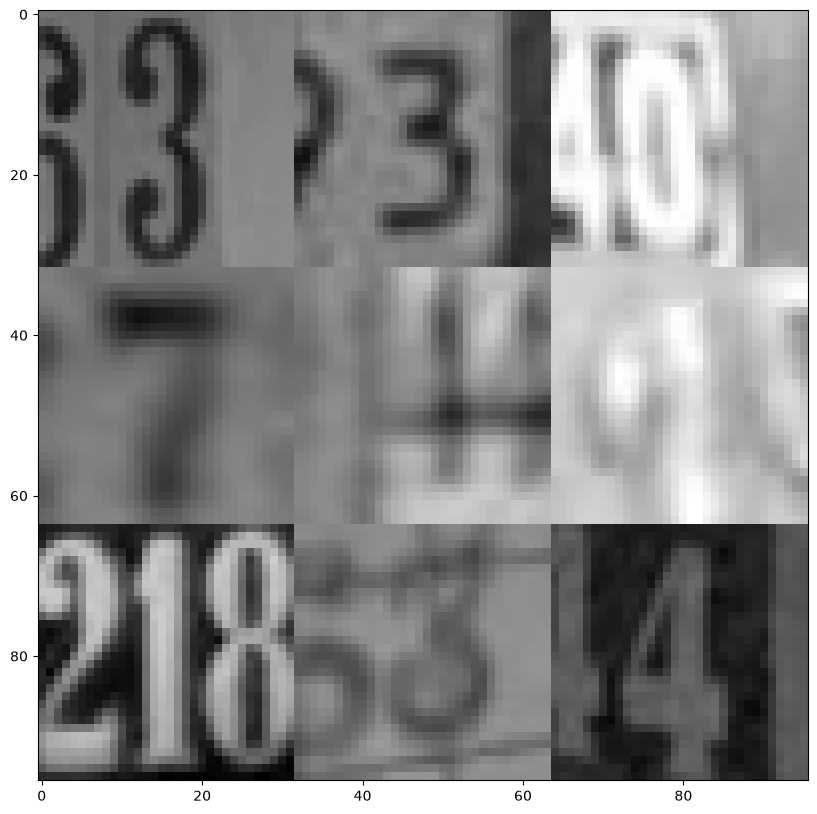

In [18]:
# now plotting some of them
image_batch, label_batch = next(iter(train_loader_0))
image_batch.shape, label_batch.shape

print(label_batch[:9]) # printing the actual corresponding numbers

plt.figure(figsize=(10, 10))
plt.imshow(image_batch[:9, 0, :, :]  # now showing the first 9 images
            .reshape(3, 3, 32, 32)
            .permute(0, 2, 1, 3)
            .reshape(32*3, 32*3), cmap='gray')
plt.show()

### b (5 pts) :
Design and train your customized CNN for this multi-class classification task, that achieves good performance on the grayscale SVHN test set. 
Explain your design choices for
the output layer and the loss function that you will use during training. Minimize the training
loss using Adam, and use early stopping based on the validation set to avoid overfitting. Test
at least 5 different architectures with varying numbers of convolutional layers and number of
kernels (i.e., change the architecture in depth and width). Provide a table comparing training
and validation losses, the number of trainable parameters, and the learning rate used for the
different architectures.

### c (2.5 pts) : 
For the best architecture from part (b), verify the calculation of parameters by hand.
Write down and add up the number parameters (weights and biases) for each layer. Clearly state where all the used values come from. Which layer contains most of the parameters? How
does this highlight one of the main benefits of CNNs? Also visualize all the convolutional
kernels of the first layer of your model. What do you observe (e.g., duplicate channels, dead or
uniform channels, specific feature detectors, ...)?

### d (4.5 pts) : 
For the best architecture from part (b), investigate the impact of an l2 regularization
approach, as well as dropout for regularization. You should use the validation set to find the
appropriate regularization hyper-parameters (e.g., l2 regularization weight, or a good dropout
rate). Furthermore, try and discuss different data augmentation approaches to achieve better
generalization of your model. Provide a table where training and validation set errors and
accuracies of various regularization settings are compared.

### e (2 pts) :
 Clearly summarize your final model architecture in detail (i.e., convolutional and/or
pooling kernel sizes and specifications, input and output dimensionalities per layer, activation
functions). Report your training specifications regarding the loss function, optimization scheme
and learning rate, batch size and number of training epochs. Provide a plot where the evolution
of the training and validation error during training is shown throughout iterations. Perform
a final training with the whole training set. Report the final test accuracy and a confusion
matrix of your test set predictions. Which classes are confused most often with each other?